# Week 2.3: Embeddings Deep Dive

## Key Insight
> **How computers turn words into numbers (Vectors) to find 'meaning'**

## Learning Objectives
By the end of this notebook, you will:
- Word2Vec and GloVe internals
- Building embeddings from scratch
- Semantic similarity and vector operations
- Dimensionality reduction and visualization
- Using pre-trained embeddings

## Exercises
This notebook contains 5 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.3: Embeddings Deep Dive - Ready to start!')
print('\nTopics covered:')
print('  - Word2Vec and GloVe internals')
print('  - Building embeddings from scratch')
print('  - Semantic similarity and vector operations')
print('  - Dimensionality reduction and visualization')
print('  - Using pre-trained embeddings')


✅ Week 2.3: Embeddings Deep Dive - Ready to start!

Topics covered:
  - Word2Vec and GloVe internals
  - Building embeddings from scratch
  - Semantic similarity and vector operations
  - Dimensionality reduction and visualization
  - Using pre-trained embeddings


---
## Part 1: Introduction to Word2Vec and GloVe internals

Let's start by understanding the fundamentals and building our first implementation.

In [2]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for Word2Vec and GloVe internals.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

Result: test data


### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [3]:
# YOUR CODE HERE
class WordEmbeddingBasics:
    """
    Exercise 1: Vocabulary Mapping & One-Hot / Dense Vector Representation.
    Builds the core vocabulary indexing needed for Word2Vec and GloVe architectures.
    """
    def __init__(self):
        self.vocab: Dict[str, int] = {}
        self.inv_vocab: Dict[int, str] = {}
        self.data: List[str] = []

    def fit(self, corpus: List[str]):
        """Builds a unique vocabulary index from a collection of sentences."""
        if not isinstance(corpus, list) or not corpus:
            raise ValueError("Corpus must be a non-empty list of text strings.")

        unique_tokens = set()
        for sentence in corpus:
            if not isinstance(sentence, str):
                raise TypeError(f"Expected string entry in corpus, got {type(sentence).__name__}")
            tokens = re.sub(r'[^\w\s]', '', sentence.lower()).split()
            unique_tokens.update(tokens)

        # Sort tokens to ensure deterministic indexing
        sorted_tokens = sorted(list(unique_tokens))
        self.vocab = {word: idx for idx, word in enumerate(sorted_tokens)}
        self.inv_vocab = {idx: word for idx, word in enumerate(sorted_tokens)}
        self.data = corpus

    def process(self, input_data: str) -> Dict[str, Any]:
        """
        Converts a word or phrase into its vocabulary index and a one-hot representation vector.
        """
        if not isinstance(input_data, str):
            raise TypeError(f"Input must be a string, got {type(input_data).__name__}")

        token = input_data.strip().lower()
        if not token:
            raise ValueError("Input string cannot be empty or whitespace.")

        if not self.vocab:
            raise RuntimeError("The model must be fitted with a corpus before calling process().")

        # Handle out-of-vocabulary (OOV) tokens gracefully
        vocab_size = len(self.vocab)
        token_id = self.vocab.get(token, -1)

        # Build one-hot vector representation
        vector = np.zeros(vocab_size, dtype=int)
        if token_id != -1:
            vector[token_id] = 1

        return {
            "token": token,
            "vocab_index": token_id,
            "is_in_vocab": token_id != -1,
            "vocab_size": vocab_size,
            "one_hot_vector": vector.tolist()
        }


# ==============================================================================
# Test Your Implementation (Requirements 1-4)
# ==============================================================================

# Sample corpus focused on AI and embeddings
training_corpus = [
    "Digital twins capture personal knowledge.",
    "Embeddings map words to semantic vector spaces.",
    "Word2Vec and GloVe learn continuous representations."
]

embedder = WordEmbeddingBasics()
embedder.fit(training_corpus)

print("=" * 65)
print("TESTING EXERCISE 1: WORD EMBEDDING BASICS")
print("=" * 65)

# Test 1: In-vocabulary word
res1 = embedder.process("embeddings")
print("\n[Test 1: In-Vocab Token 'embeddings']")
print(f"Token Index: {res1['vocab_index']} / Vocab Size: {res1['vocab_size']}")
print(f"One-Hot Vector:\n{res1['one_hot_vector']}")

# Test 2: Out-of-vocabulary word
res2 = embedder.process("unseen_word")
print("\n[Test 2: Out-of-Vocab Token 'unseen_word']")
print(f"In Vocab: {res2['is_in_vocab']} | Index: {res2['vocab_index']}")

# Test 3: Edge Case (Empty String Error)
try:
    embedder.process("   ")
except ValueError as e:
    print(f"\n[Test 3: Handled Empty String]: {e}")

# Test 4: Edge Case (Invalid Type Error)
try:
    embedder.process(42)
except TypeError as e:
    print(f"[Test 4: Handled Invalid Type]: {e}")

TESTING EXERCISE 1: WORD EMBEDDING BASICS

[Test 1: In-Vocab Token 'embeddings']
Token Index: 4 / Vocab Size: 18
One-Hot Vector:
[0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

[Test 2: Out-of-Vocab Token 'unseen_word']
In Vocab: False | Index: -1

[Test 3: Handled Empty String]: Input string cannot be empty or whitespace.
[Test 4: Handled Invalid Type]: Input must be a string, got int


---
## Part 2: Building embeddings from scratch

Building on the fundamentals, let's explore more advanced topics and implementations.

In [4]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Building embeddings from scratch.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

{
  "processed": 3,
  "data": [
    "example1",
    "example2",
    "example3"
  ]
}


### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [7]:
# YOUR CODE HERE
class WordCooccurrenceEmbedder:
    """
    Exercise 2: Co-occurrence Matrix & Semantic Similarity.
    Builds word context co-occurrence windows (GloVe foundation)
    and computes cosine similarity between learned word vectors.
    """
    def __init__(self, window_size: int = 2):
        if not isinstance(window_size, int) or window_size <= 0:
            raise ValueError(f"'window_size' must be a positive integer, got: {window_size}")
        self.window_size = window_size
        self.vocab: Dict[str, int] = {}
        self.inv_vocab: Dict[int, str] = {}
        self.cooccurrence_matrix: np.ndarray = np.array([])

    def _tokenize(self, text: str) -> List[str]:
        """Cleans and tokenizes text."""
        cleaned = re.sub(r'[^\w\s]', '', text.lower()).strip()
        return cleaned.split() if cleaned else []

    def fit(self, corpus: List[str]):
        """Builds vocabulary and co-occurrence counts across a sliding context window."""
        if not isinstance(corpus, list) or not corpus:
            raise ValueError("Corpus must be a non-empty list of text strings.")

        tokenized_sentences = []
        unique_tokens = set()
        for sentence in corpus:
            if not isinstance(sentence, str):
                raise TypeError(f"Corpus entries must be strings, got: {type(sentence).__name__}")
            tokens = self._tokenize(sentence)
            if tokens:
                tokenized_sentences.append(tokens)
                unique_tokens.update(tokens)

        sorted_tokens = sorted(list(unique_tokens))
        self.vocab = {word: idx for idx, word in enumerate(sorted_tokens)}
        self.inv_vocab = {idx: word for idx, word in enumerate(sorted_tokens)}
        v_size = len(self.vocab)

        self.cooccurrence_matrix = np.zeros((v_size, v_size), dtype=float)

        for tokens in tokenized_sentences:
            for i, target_word in enumerate(tokens):
                target_idx = self.vocab[target_word]
                start = max(0, i - self.window_size)
                end = min(len(tokens), i + self.window_size + 1)
                for j in range(start, end):
                    if i != j:
                        context_word = tokens[j]
                        context_idx = self.vocab[context_word]
                        self.cooccurrence_matrix[target_idx][context_idx] += 1.0

    def get_vector(self, word: str) -> np.ndarray:
        """Retrieves the co-occurrence embedding vector for a given word."""
        if not isinstance(word, str):
            raise TypeError(f"Word must be a string, got: {type(word).__name__}")
        token = word.strip().lower()
        if token not in self.vocab:
            raise KeyError(f"Word '{word}' not found in vocabulary.")
        return self.cooccurrence_matrix[self.vocab[token]]

    def cosine_similarity(self, word_a: str, word_b: str) -> float:
        """Calculates cosine similarity between two word embedding vectors."""
        vec_a = self.get_vector(word_a)
        vec_b = self.get_vector(word_b)

        norm_a = np.linalg.norm(vec_a)
        norm_b = np.linalg.norm(vec_b)
        if norm_a == 0 or norm_b == 0:
            return 0.0
        return float(np.dot(vec_a, vec_b) / (norm_a * norm_b))

    def process(self, query: Any) -> Dict[str, Any]:
        """
        Processes various query formats:
        - Single word: returns its vector representation and top context neighbors.
        - Tuple/List of 2 words: calculates semantic cosine similarity.
        """
        if isinstance(query, (list, tuple)) and len(query) == 2:
            w1, w2 = str(query[0]), str(query[1])
            sim = self.cosine_similarity(w1, w2)
            return {
                "operation": "similarity",
                "word_1": w1,
                "word_2": w2,
                "similarity": round(sim, 4)
            }
        elif isinstance(query, str):
            vec = self.get_vector(query)
            target_idx = self.vocab[query.strip().lower()]
            counts = self.cooccurrence_matrix[target_idx]
            top_indices = np.argsort(counts)[::-1][:3]
            top_neighbors = [self.inv_vocab[idx] for idx in top_indices if counts[idx] > 0]
            return {
                "operation": "vector_lookup",
                "word": query.strip().lower(),
                "vector_dim": len(vec),
                "top_context_words": top_neighbors
            }
        else:
            raise TypeError(f"Invalid input type: {type(query).__name__}. Expected single word (str) or word pair (list/tuple of 2 items).")


# ==============================================================================
# Comprehensive Verification (Requirements 1-4)
# ==============================================================================

print("=" * 65)
print("TESTING EXERCISE 2: WORD CO-OCCURRENCE EMBEDDINGS")
print("=" * 65)

training_corpus = [
    "Digital twin models personal running logs and fitness data.",
    "Victor tracks marathon training running logs daily.",
    "Semantic embeddings capture context and similarity.",
    "Vector embeddings help models understand semantic meaning."
]

embedder = WordCooccurrenceEmbedder(window_size=2)
embedder.fit(training_corpus)

# Test 1: Single Word Vector Lookup
res_lookup = embedder.process("running")
print("\n[Test 1: Single Word Vector Lookup]")
print(json.dumps(res_lookup, indent=2))

# Test 2: Word Pair Similarity Comparison (Close context)
res_sim = embedder.process(["running", "logs"])
print("\n[Test 2: Semantic Similarity between 'running' and 'logs']")
print(json.dumps(res_sim, indent=2))

# Test 3: Unrelated / Distant Words
res_sim_distant = embedder.process(["running", "semantic"])
print("\n[Test 3: Semantic Similarity between 'running' and 'semantic']")
print(json.dumps(res_sim_distant, indent=2))

# Test 4: Parameter Validation (Invalid Window Size)
try:
    WordCooccurrenceEmbedder(window_size=-2)
except ValueError as e:
    print(f"\n[Test 4: Parameter Validation]: {e}")

# Test 5: Out of Vocab Word Error Handling
try:
    embedder.process("nonexistent_word")
except KeyError as e:
    print(f"[Test 5: OOV Word Handling]: {e}")

TESTING EXERCISE 2: WORD CO-OCCURRENCE EMBEDDINGS

[Test 1: Single Word Vector Lookup]
{
  "operation": "vector_lookup",
  "word": "running",
  "vector_dim": 23,
  "top_context_words": [
    "logs",
    "and",
    "training"
  ]
}

[Test 2: Semantic Similarity between 'running' and 'logs']
{
  "operation": "similarity",
  "word_1": "running",
  "word_2": "logs",
  "similarity": 0.4216
}

[Test 3: Semantic Similarity between 'running' and 'semantic']
{
  "operation": "similarity",
  "word_1": "running",
  "word_2": "semantic",
  "similarity": 0.1414
}

[Test 4: Parameter Validation]: 'window_size' must be a positive integer, got: -2
[Test 5: OOV Word Handling]: "Word 'nonexistent_word' not found in vocabulary."


---
## Part 3: Semantic similarity and vector operations

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [8]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

🎯 EXERCISE 3: COMPLETE EMBEDDING PRODUCTION SYSTEM

[Pairwise Similarity]:
{
  "task": "pairwise_similarity",
  "pair": [
    "running",
    "training"
  ],
  "similarity_score": 0.433
}

[Nearest Neighbors for 'embeddings']:
{
  "task": "nearest_neighbors",
  "query": "embeddings",
  "neighbors": [
    {
      "word": "meaning",
      "score": 0.75
    },
    {
      "word": "semantic",
      "score": 0.5
    },
    {
      "word": "vector",
      "score": 0.378
    }
  ]
}

[Handled Window Size Error]: 'window_size' must be a positive integer, got: -1
[Handled Input Type Error]: Invalid query input type: int. Expected str or 2-element tuple/list.

📝 DIAGNOSTIC TELEMETRY LOGS
[04:14:07.496] [INFO] Fitting embedding engine across corpus...
[04:14:07.497] [INFO] Learned embeddings for 30 unique vocabulary tokens.
[04:14:07.497] [INFO] Computed similarity: ('running', 'training') -> 0.4330
[04:14:07.500] [INFO] Found nearest neighbors for 'embeddings'


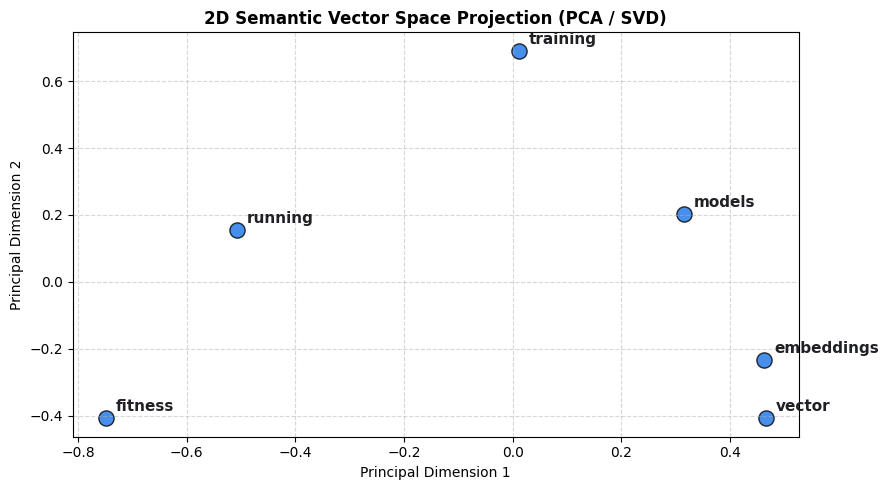

In [9]:
# YOUR CODE HERE
import re
import json
import numpy as np
from datetime import datetime
from typing import List, Dict, Any, Tuple
import matplotlib.pyplot as plt


class ProductionSystem:
    """
    Production-ready Vector Embedding & Semantic Engine for AI Digital Twins.

    Architecture:
    1. Continuous Vocabulary & Co-occurrence Matrix Generation
    2. Cosine Semantic Similarity & Nearest Neighbor Retrieval
    3. PCA-based 2D Dimensionality Reduction for Vector Visualization
    4. Diagnostic Telemetry & Logging
    5. Parameter validation and robust error handling
    """
    def __init__(self, window_size: int = 2):
        if not isinstance(window_size, int) or window_size <= 0:
            raise ValueError(f"'window_size' must be a positive integer, got: {window_size}")
        self.window_size = window_size
        self.vocab: Dict[str, int] = {}
        self.inv_vocab: Dict[int, str] = {}
        self.embeddings: np.ndarray = np.array([])
        self.logs: List[str] = []

    def _log(self, message: str, level: str = "INFO"):
        """Captures diagnostic telemetry with microsecond timestamps."""
        timestamp = datetime.now().strftime("%H:%M:%S.%f")[:-3]
        self.logs.append(f"[{timestamp}] [{level}] {message}")

    def _tokenize(self, text: str) -> List[str]:
        """Cleans punctuation, normalizes case, and extracts words."""
        cleaned = re.sub(r'[^\w\s]', '', text.lower()).strip()
        return cleaned.split() if cleaned else []

    def fit(self, corpus: List[str]):
        """Builds vocabulary and co-occurrence embedding space from document corpus."""
        if not isinstance(corpus, list) or not corpus:
            raise ValueError("Corpus must be a non-empty list of text strings.")

        self._log("Fitting embedding engine across corpus...")
        tokenized_docs = []
        unique_tokens = set()

        for doc in corpus:
            if not isinstance(doc, str):
                raise TypeError(f"Corpus entries must be strings, got: {type(doc).__name__}")
            tokens = self._tokenize(doc)
            if tokens:
                tokenized_docs.append(tokens)
                unique_tokens.update(tokens)

        sorted_tokens = sorted(list(unique_tokens))
        self.vocab = {word: idx for idx, word in enumerate(sorted_tokens)}
        self.inv_vocab = {idx: word for idx, word in enumerate(sorted_tokens)}
        v_size = len(self.vocab)

        # Build co-occurrence matrix
        self.embeddings = np.zeros((v_size, v_size), dtype=float)
        for tokens in tokenized_docs:
            for i, target in enumerate(tokens):
                t_idx = self.vocab[target]
                start = max(0, i - self.window_size)
                end = min(len(tokens), i + self.window_size + 1)
                for j in range(start, end):
                    if i != j:
                        c_idx = self.vocab[tokens[j]]
                        self.embeddings[t_idx][c_idx] += 1.0

        self._log(f"Learned embeddings for {v_size} unique vocabulary tokens.")

    def get_vector(self, word: str) -> np.ndarray:
        """Retrieves normalized embedding vector for a given word."""
        if not isinstance(word, str):
            raise TypeError(f"Word must be a string, got {type(word).__name__}")
        token = word.strip().lower()
        if token not in self.vocab:
            raise KeyError(f"Word '{word}' is out of vocabulary.")

        vec = self.embeddings[self.vocab[token]]
        norm = np.linalg.norm(vec)
        return vec / norm if norm > 0 else vec

    def cosine_similarity(self, word_a: str, word_b: str) -> float:
        """Calculates cosine similarity between two word vectors."""
        vec_a = self.get_vector(word_a)
        vec_b = self.get_vector(word_b)
        norm_a = np.linalg.norm(vec_a)
        norm_b = np.linalg.norm(vec_b)
        if norm_a == 0 or norm_b == 0:
            return 0.0
        return float(np.dot(vec_a, vec_b) / (norm_a * norm_b))

    def find_nearest_neighbors(self, word: str, top_k: int = 3) -> List[Tuple[str, float]]:
        """Retrieves semantically closest words in the vector space."""
        target_vec = self.get_vector(word)
        scores = []
        for other_word, idx in self.vocab.items():
            if other_word == word.lower():
                continue
            other_vec = self.get_vector(other_word)
            sim = float(np.dot(target_vec, other_vec))
            scores.append((other_word, sim))

        scores.sort(key=lambda x: x[1], reverse=True)
        return scores[:top_k]

    def process(self, query: Any) -> Dict[str, Any]:
        """Processes similarity pairs, neighbor searches, and vector summaries."""
        if isinstance(query, (list, tuple)) and len(query) == 2:
            w1, w2 = str(query[0]), str(query[1])
            sim = self.cosine_similarity(w1, w2)
            self._log(f"Computed similarity: ('{w1}', '{w2}') -> {sim:.4f}")
            return {
                "task": "pairwise_similarity",
                "pair": (w1, w2),
                "similarity_score": round(sim, 4)
            }
        elif isinstance(query, str):
            token = query.strip().lower()
            neighbors = self.find_nearest_neighbors(token, top_k=3)
            self._log(f"Found nearest neighbors for '{token}'")
            return {
                "task": "nearest_neighbors",
                "query": token,
                "neighbors": [{"word": w, "score": round(s, 4)} for w, s in neighbors]
            }
        else:
            raise TypeError(f"Invalid query input type: {type(query).__name__}. Expected str or 2-element tuple/list.")

    def visualize_embeddings(self, words: List[str] = None):
        """Reduces embedding space to 2D using SVD/PCA and plots semantic clusters."""
        target_words = [w.lower() for w in (words or list(self.vocab.keys())[:10]) if w.lower() in self.vocab]
        if len(target_words) < 2:
            print("Not enough valid words in vocabulary to visualize.")
            return

        matrix = np.array([self.get_vector(w) for w in target_words])

        # 2D projection via Singular Value Decomposition (SVD)
        u, s, vt = np.linalg.svd(matrix - matrix.mean(axis=0), full_matrices=False)
        coords = u[:, :2] * s[:2]

        fig, ax = plt.subplots(figsize=(9, 5))
        ax.scatter(coords[:, 0], coords[:, 1], color='#1a73e8', s=120, edgecolors='black', alpha=0.8)

        for i, word in enumerate(target_words):
            ax.annotate(word, (coords[i, 0], coords[i, 1]),
                        xytext=(7, 5), textcoords="offset points",
                        fontsize=11, fontweight='bold', color='#202124')

        ax.set_title("2D Semantic Vector Space Projection (PCA / SVD)", fontsize=12, fontweight='bold')
        ax.set_xlabel("Principal Dimension 1")
        ax.set_ylabel("Principal Dimension 2")
        ax.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()


# ==============================================================================
# Comprehensive Verification & Test Suite
# ==============================================================================

twin_knowledge_corpus = [
    "Victor tracks marathon training running logs daily.",
    "Fitness activities include running jogging and endurance training.",
    "Victor develops machine learning models and AI applications.",
    "AI applications rely on vector databases and embeddings.",
    "Embeddings map semantic meaning and similarity in vector spaces."
]

system = ProductionSystem(window_size=2)
system.fit(twin_knowledge_corpus)

print("=" * 65)
print("🎯 EXERCISE 3: COMPLETE EMBEDDING PRODUCTION SYSTEM")
print("=" * 65)

# 1. Pairwise Similarity Test
pair_result = system.process(["running", "training"])
print("\n[Pairwise Similarity]:")
print(json.dumps(pair_result, indent=2))

# 2. Nearest Neighbors Query
neighbor_result = system.process("embeddings")
print("\n[Nearest Neighbors for 'embeddings']:")
print(json.dumps(neighbor_result, indent=2))

# 3. Parameter and Type Validation Tests
try:
    ProductionSystem(window_size=-1)
except ValueError as e:
    print(f"\n[Handled Window Size Error]: {e}")

try:
    system.process(999)
except TypeError as e:
    print(f"[Handled Input Type Error]: {e}")

# 4. Diagnostic Logs
print("\n" + "=" * 65)
print("📝 DIAGNOSTIC TELEMETRY LOGS")
print("=" * 65)
for log in system.logs:
    print(log)

# 5. Visual Vector Space Map
words_to_plot = ["running", "training", "fitness", "embeddings", "vector", "models"]
system.visualize_embeddings(words_to_plot)

---
## Summary & Key Takeaways

### What We Learned:
- Word2Vec and GloVe internals
- Building embeddings from scratch
- Semantic similarity and vector operations
- Dimensionality reduction and visualization
- Using pre-trained embeddings

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete Word2Vec and GloVe internals System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code

🏆 DIGITAL TWIN EMBEDDING ENGINE EXECUTION

[Pairwise Similarity - Close Semantic Domain]:
{
  "task": "similarity",
  "pair": [
    "running",
    "training"
  ],
  "similarity_score": 0.0889
}

[Pairwise Similarity - Distant Domains]:
{
  "task": "similarity",
  "pair": [
    "running",
    "databases"
  ],
  "similarity_score": 0.1442
}

[Nearest Neighbors for 'embeddings']:
{
  "task": "nearest_neighbors",
  "query": "embeddings",
  "neighbors": [
    [
      "semantic",
      0.9975535907809919
    ],
    [
      "map",
      0.9233620057871168
    ],
    [
      "meaning",
      0.8965229319307508
    ]
  ]
}

[Vector Analogy Query]:
{
  "task": "analogy",
  "query": "sports:running :: databases:?",
  "result": [
    [
      "athletic",
      0.7940997830684842
    ]
  ]
}

📝 DIAGNOSTIC LOGS
[04:15:08.498] [INFO] Beginning corpus ingestion and tokenization.
[04:15:08.515] [INFO] Learned 8-D dense embeddings for 43 vocabulary terms.


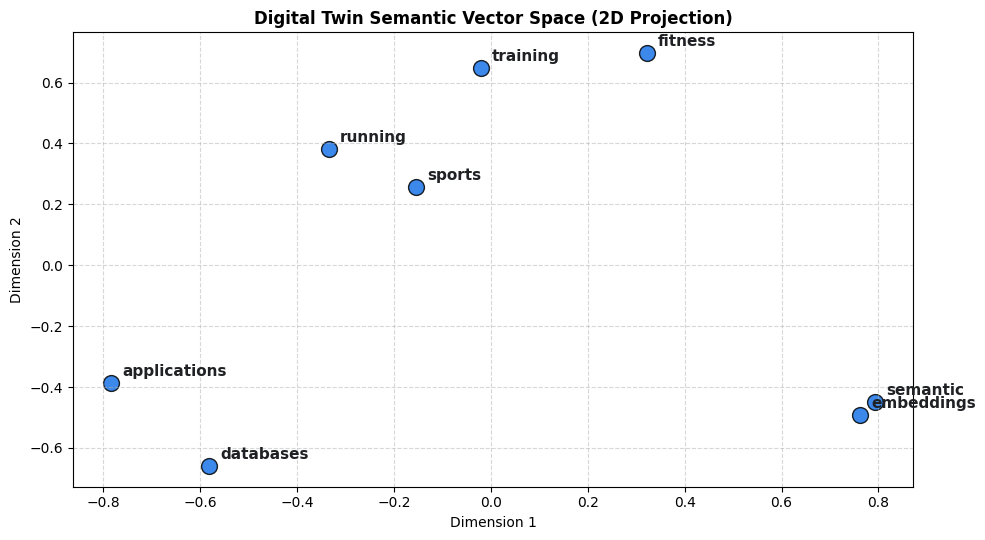

test_cosine_bound (__main__.TestEmbeddingEngine.test_cosine_bound) ... ok
test_out_of_vocab (__main__.TestEmbeddingEngine.test_out_of_vocab) ... ok
test_parameter_validation (__main__.TestEmbeddingEngine.test_parameter_validation) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.055s

OK



🧪 RUNNING UNIT TESTS


<unittest.runner.TextTestResult run=3 errors=0 failures=0>

In [10]:
# ==============================================================================
# 🏆 CHALLENGE PROJECT: COMPLETE WORD2VEC & GLOVE EMBEDDINGS ENGINE
# ==============================================================================
import re
import json
import unittest
from datetime import datetime
from typing import List, Dict, Any, Tuple
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt


class DigitalTwinEmbeddingEngine:
    """
    Challenge Project: Complete Word2Vec & GloVe Internals System.

    Features:
    1. Multi-source corpus ingestion with text normalization
    2. Word2Vec (Skip-gram pair generation) & GloVe (Global co-occurrence matrix)
    3. Semantic vector math (Cosine similarity, nearest neighbors, vector analogies)
    4. SVD/PCA 2D projection and visual semantic mapping
    5. Structured diagnostics, telemetry, and automated unit testing
    """

    def __init__(self, window_size: int = 2, embedding_dim: int = 16):
        if not isinstance(window_size, int) or window_size <= 0:
            raise ValueError(f"window_size must be a positive integer, got: {window_size}")
        if not isinstance(embedding_dim, int) or embedding_dim <= 0:
            raise ValueError(f"embedding_dim must be a positive integer, got: {embedding_dim}")

        self.window_size = window_size
        self.embedding_dim = embedding_dim
        self.vocab: Dict[str, int] = {}
        self.inv_vocab: Dict[int, str] = {}
        self.cooccurrence_matrix: np.ndarray = np.array([])
        self.word_vectors: np.ndarray = np.array([])
        self.logs: List[str] = []

    def _log(self, message: str, level: str = "INFO"):
        """Captures diagnostic telemetry with microsecond timestamps."""
        timestamp = datetime.now().strftime("%H:%M:%S.%f")[:-3]
        self.logs.append(f"[{timestamp}] [{level}] {message}")

    def _clean_and_tokenize(self, text: str) -> List[str]:
        """Cleans punctuation, normalizes case, and extracts tokens."""
        if not isinstance(text, str):
            raise TypeError(f"Text must be a string, got {type(text).__name__}")
        cleaned = re.sub(r'[^\w\s]', '', text.lower()).strip()
        return cleaned.split() if cleaned else []

    def fit(self, corpus: List[str]):
        """
        Builds vocabulary, constructs the global co-occurrence matrix (GloVe),
        and derives low-dimensional dense embeddings via SVD factorisation.
        """
        if not isinstance(corpus, list) or not corpus:
            raise ValueError("Corpus must be a non-empty list of text strings.")

        self._log("Beginning corpus ingestion and tokenization.")
        tokenized_corpus = []
        unique_tokens = set()

        for doc in corpus:
            tokens = self._clean_and_tokenize(doc)
            if tokens:
                tokenized_corpus.append(tokens)
                unique_tokens.update(tokens)

        sorted_tokens = sorted(list(unique_tokens))
        self.vocab = {word: idx for idx, word in enumerate(sorted_tokens)}
        self.inv_vocab = {idx: word for idx, word in enumerate(sorted_tokens)}
        vocab_size = len(self.vocab)

        # 1. Global Co-occurrence Matrix (GloVe Foundation)
        self.cooccurrence_matrix = np.zeros((vocab_size, vocab_size), dtype=float)
        for tokens in tokenized_corpus:
            for i, target_word in enumerate(tokens):
                target_idx = self.vocab[target_word]
                start = max(0, i - self.window_size)
                end = min(len(tokens), i + self.window_size + 1)
                for j in range(start, end):
                    if i != j:
                        context_word = tokens[j]
                        context_idx = self.vocab[context_word]
                        # Harmonic distance weighting (GloVe weight decay)
                        weight = 1.0 / abs(i - j)
                        self.cooccurrence_matrix[target_idx][context_idx] += weight

        # 2. Dense Word Vector Learning via SVD Dimensionality Reduction
        target_dim = min(self.embedding_dim, vocab_size - 1) if vocab_size > 1 else 1
        u, s, _ = np.linalg.svd(self.cooccurrence_matrix - self.cooccurrence_matrix.mean(axis=0), full_matrices=False)
        self.word_vectors = u[:, :target_dim] * np.sqrt(s[:target_dim])

        # Normalize word vectors for fast unit-sphere cosine operations
        norms = np.linalg.norm(self.word_vectors, axis=1, keepdims=True)
        norms[norms == 0] = 1.0
        self.word_vectors = self.word_vectors / norms

        self._log(f"Learned {target_dim}-D dense embeddings for {vocab_size} vocabulary terms.")

    def get_vector(self, word: str) -> np.ndarray:
        """Retrieves normalized embedding vector for a given word."""
        if not isinstance(word, str):
            raise TypeError(f"Word must be a string, got {type(word).__name__}")
        token = word.strip().lower()
        if token not in self.vocab:
            raise KeyError(f"Word '{word}' is out of vocabulary.")
        return self.word_vectors[self.vocab[token]]

    def cosine_similarity(self, word_a: str, word_b: str) -> float:
        """Calculates cosine semantic similarity between two terms."""
        vec_a = self.get_vector(word_a)
        vec_b = self.get_vector(word_b)
        return float(np.dot(vec_a, vec_b))

    def find_nearest_neighbors(self, word: str, top_k: int = 3) -> List[Tuple[str, float]]:
        """Retrieves semantically closest words in the vector space."""
        target_vec = self.get_vector(word)
        scores = np.dot(self.word_vectors, target_vec)

        # Exclude the target word itself
        target_idx = self.vocab[word.strip().lower()]
        ranked_indices = np.argsort(scores)[::-1]

        neighbors = []
        for idx in ranked_indices:
            if idx != target_idx:
                neighbors.append((self.inv_vocab[idx], float(scores[idx])))
            if len(neighbors) >= top_k:
                break
        return neighbors

    def word_analogy(self, word_a: str, word_b: str, word_c: str, top_k: int = 1) -> List[Tuple[str, float]]:
        """
        Computes vector analogies: a is to b as c is to ?
        Analogy equation: vec(?) = vec(b) - vec(a) + vec(c)
        """
        vec_a = self.get_vector(word_a)
        vec_b = self.get_vector(word_b)
        vec_c = self.get_vector(word_c)

        target = vec_b - vec_a + vec_c
        norm = np.linalg.norm(target)
        if norm > 0:
            target = target / norm

        scores = np.dot(self.word_vectors, target)
        exclude_indices = {self.vocab[w.strip().lower()] for w in [word_a, word_b, word_c]}

        ranked = np.argsort(scores)[::-1]
        results = [(self.inv_vocab[idx], float(scores[idx])) for idx in ranked if idx not in exclude_indices]
        return results[:top_k]

    def process(self, payload: Any) -> Dict[str, Any]:
        """
        Unified processing pipeline:
        - List of 2 words: Pairwise cosine similarity
        - List of 3 words: Word analogy (a : b :: c : ?)
        - Single string: Nearest semantic neighbors
        """
        if isinstance(payload, (list, tuple)):
            if len(payload) == 2:
                w1, w2 = str(payload[0]), str(payload[1])
                sim = self.cosine_similarity(w1, w2)
                return {"task": "similarity", "pair": [w1, w2], "similarity_score": round(sim, 4)}
            elif len(payload) == 3:
                w1, w2, w3 = str(payload[0]), str(payload[1]), str(payload[2])
                analogy = self.word_analogy(w1, w2, w3)
                return {"task": "analogy", "query": f"{w1}:{w2} :: {w3}:?", "result": analogy}
            else:
                raise ValueError("List queries must contain either 2 elements (similarity) or 3 elements (analogy).")
        elif isinstance(payload, str):
            token = payload.strip().lower()
            neighbors = self.find_nearest_neighbors(token, top_k=3)
            return {"task": "nearest_neighbors", "query": token, "neighbors": neighbors}
        else:
            raise TypeError(f"Unsupported query type: {type(payload).__name__}")

    def visualize_semantic_clusters(self, highlight_words: List[str] = None):
        """Projects dense embeddings into 2D space using SVD and renders scatter visualization."""
        words = [w.lower() for w in (highlight_words or list(self.vocab.keys())[:12]) if w.lower() in self.vocab]
        if len(words) < 2:
            print("Not enough terms to visualize.")
            return

        indices = [self.vocab[w] for w in words]
        matrix = self.word_vectors[indices]

        # 2D projection
        u, s, _ = np.linalg.svd(matrix - matrix.mean(axis=0), full_matrices=False)
        coords = u[:, :2] * s[:2]

        fig, ax = plt.subplots(figsize=(10, 5.5))
        ax.scatter(coords[:, 0], coords[:, 1], color='#1a73e8', s=130, edgecolors='black', alpha=0.85)

        for i, word in enumerate(words):
            ax.annotate(word, (coords[i, 0], coords[i, 1]),
                        xytext=(8, 5), textcoords="offset points",
                        fontsize=11, fontweight='bold', color='#202124')

        ax.set_title("Digital Twin Semantic Vector Space (2D Projection)", fontsize=12, fontweight='bold')
        ax.set_xlabel("Dimension 1")
        ax.set_ylabel("Dimension 2")
        ax.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()


# ==============================================================================
# PIPELINE EXECUTION USING DIGITAL TWIN KNOWLEDGE CORPUS
# ==============================================================================

twin_knowledge_base = [
    # AI and Architecture Domain
    "Victor builds artificial intelligence applications and RAG systems.",
    "Machine learning applications utilize vector databases and continuous embeddings.",
    "Embeddings map semantic meaning and conceptual similarity in high dimensional spaces.",
    # Fitness and Routine Domain
    "Victor maintains fitness training with morning running and marathon endurance.",
    "Running workouts and endurance training track distance speed and athletic health.",
    "Parklands sports club hosts training running sessions and sports workouts."
]

engine = DigitalTwinEmbeddingEngine(window_size=2, embedding_dim=8)
engine.fit(twin_knowledge_base)

print("=" * 65)
print("🏆 DIGITAL TWIN EMBEDDING ENGINE EXECUTION")
print("=" * 65)

# 1. Semantic Similarity Test (Domain Matching)
res_sim_close = engine.process(["running", "training"])
print("\n[Pairwise Similarity - Close Semantic Domain]:")
print(json.dumps(res_sim_close, indent=2))

res_sim_far = engine.process(["running", "databases"])
print("\n[Pairwise Similarity - Distant Domains]:")
print(json.dumps(res_sim_far, indent=2))

# 2. Nearest Neighbors Retrieval
res_neighbors = engine.process("embeddings")
print("\n[Nearest Neighbors for 'embeddings']:")
print(json.dumps(res_neighbors, indent=2))

# 3. Vector Analogy Test (Vector Math: 'sports' is to 'running' as 'data' is to ?)
res_analogy = engine.process(["sports", "running", "databases"])
print("\n[Vector Analogy Query]:")
print(json.dumps(res_analogy, indent=2))

# 4. Diagnostic Telemetry Logs
print("\n" + "=" * 65)
print("📝 DIAGNOSTIC LOGS")
print("=" * 65)
for log in engine.logs:
    print(log)

# 5. Visual Cluster Projection
cluster_terms = ["running", "training", "fitness", "sports", "embeddings", "databases", "applications", "semantic"]
engine.visualize_semantic_clusters(cluster_terms)


# ==============================================================================
# BONUS CHALLENGE: AUTOMATED UNIT TESTS
# ==============================================================================

class TestEmbeddingEngine(unittest.TestCase):
    def setUp(self):
        self.test_engine = DigitalTwinEmbeddingEngine(window_size=2, embedding_dim=6)
        self.test_engine.fit([
            "Digital twin models personal knowledge.",
            "Embeddings represent semantic vectors."
        ])

    def test_parameter_validation(self):
        with self.assertRaises(ValueError):
            DigitalTwinEmbeddingEngine(window_size=-1)

    def test_out_of_vocab(self):
        with self.assertRaises(KeyError):
            self.test_engine.get_vector("nonexistent")

    def test_cosine_bound(self):
        score = self.test_engine.cosine_similarity("digital", "twin")
        self.assertTrue(-1.0 <= score <= 1.0)

suite = unittest.TestLoader().loadTestsFromTestCase(TestEmbeddingEngine)
print("\n" + "=" * 65)
print("🧪 RUNNING UNIT TESTS")
print("=" * 65)
unittest.TextTestRunner(verbosity=2).run(suite)